In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
%matplotlib inline
import seaborn as sns


In [2]:
train_df = pd.read_csv("C:/Users/hp/Desktop/SmartCity_train.csv")
test_df = pd.read_csv("C:/Users/hp/Desktop/SmartCity_test.csv")

In [3]:
train_df.head()

,DateTime,Junction,Vehicles,ID
0,2015-11-01 00:00:00,1,15,20151101001
1,2015-11-01 01:00:00,1,13,20151101011
2,2015-11-01 02:00:00,1,10,20151101021
3,2015-11-01 03:00:00,1,7,20151101031
4,2015-11-01 04:00:00,1,9,20151101041


In [4]:
test_df.head()

,DateTime,Junction,ID
0,2017-07-01 00:00:00,1,20170701001
1,2017-07-01 01:00:00,1,20170701011
2,2017-07-01 02:00:00,1,20170701021
3,2017-07-01 03:00:00,1,20170701031
4,2017-07-01 04:00:00,1,20170701041


In [5]:
train_df['DateTime'] = pd.to_datetime(train_df['DateTime'])
test_df['DateTime'] = pd.to_datetime(test_df['DateTime'])


train_df['Hour'] = train_df['DateTime'].dt.hour
train_df['DayOfWeek'] = train_df['DateTime'].dt.dayofweek
train_df['Month'] = train_df['DateTime'].dt.month

test_df['Hour'] = test_df['DateTime'].dt.hour
test_df['DayOfWeek'] = test_df['DateTime'].dt.dayofweek
test_df['Month'] = test_df['DateTime'].dt.month


train_df.head()


    

,DateTime,Junction,Vehicles,ID,Hour,DayOfWeek,Month
0,2015-11-01 00:00:00,1,15,20151101001,0,6,11
1,2015-11-01 01:00:00,1,13,20151101011,1,6,11
2,2015-11-01 02:00:00,1,10,20151101021,2,6,11
3,2015-11-01 03:00:00,1,7,20151101031,3,6,11
4,2015-11-01 04:00:00,1,9,20151101041,4,6,11


In [6]:
test_df.head()

,DateTime,Junction,ID,Hour,DayOfWeek,Month
0,2017-07-01 00:00:00,1,20170701001,0,5,7
1,2017-07-01 01:00:00,1,20170701011,1,5,7
2,2017-07-01 02:00:00,1,20170701021,2,5,7
3,2017-07-01 03:00:00,1,20170701031,3,5,7
4,2017-07-01 04:00:00,1,20170701041,4,5,7


In [7]:
train_df.isnull().sum()

DateTime     0
Junction     0
Vehicles     0
ID           0
Hour         0
DayOfWeek    0
Month        0
dtype: int64

In [8]:
test_df.isnull().sum()

DateTime     0
Junction     0
ID           0
Hour         0
DayOfWeek    0
Month        0
dtype: int64

In [9]:
train_df.duplicated().sum()
test_df.duplicated().sum()

np.int64(0)

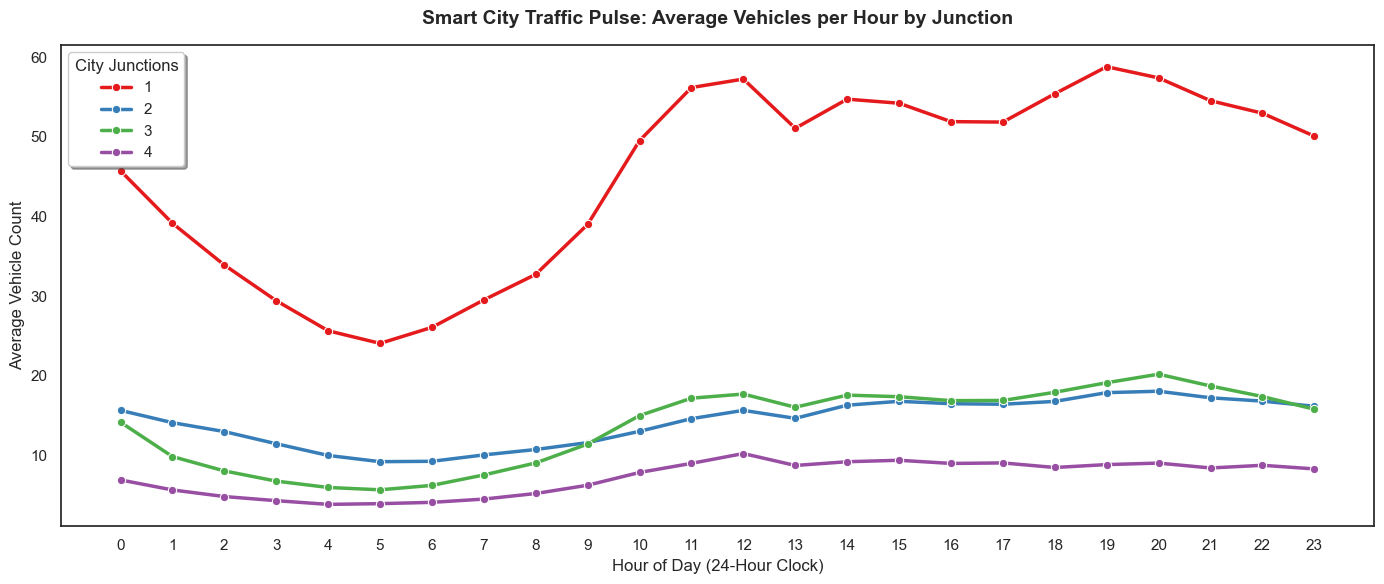

In [10]:
sns.set_theme(style="white")
plt.figure(figsize=(14, 6))
hourly_traffic = train_df.groupby(['Junction', 'Hour'])['Vehicles'].mean().reset_index()
sns.lineplot(
    data=hourly_traffic, 
    x='Hour', 
    y='Vehicles', 
    hue='Junction', 
    marker='o', 
    linewidth=2.5,
    palette='Set1'
)

plt.title('Smart City Traffic Pulse: Average Vehicles per Hour by Junction', fontsize=14, fontweight='bold', pad=15)
plt.xlabel('Hour of Day (24-Hour Clock)', fontsize=12)
plt.ylabel('Average Vehicle Count', fontsize=12)
plt.xticks(range(0, 24))
plt.legend(title='City Junctions', frameon=True, shadow=True)
plt.tight_layout()
plt.show()

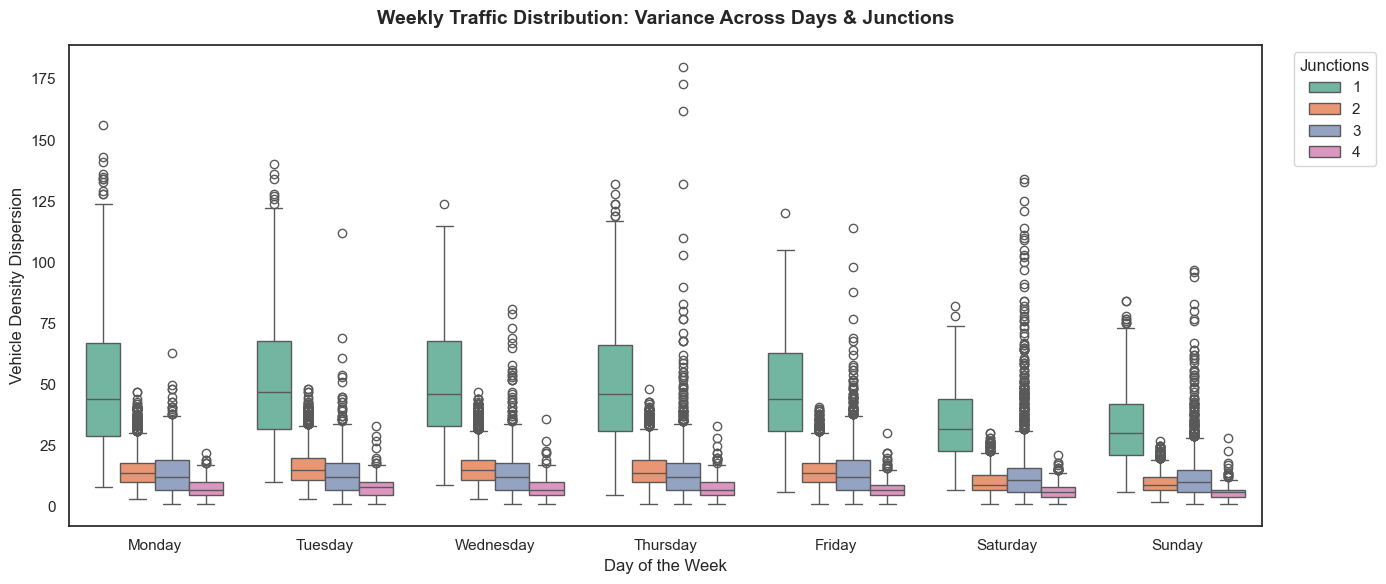

In [11]:
plt.figure(figsize=(14, 6))

# Map numeric days to text labels for the graph axis
day_labels = {0: 'Monday', 1: 'Tuesday', 2: 'Wednesday', 3: 'Thursday', 4: 'Friday', 5: 'Saturday', 6: 'Sunday'}
train_df['DayName'] = train_df['DayOfWeek'].map(day_labels)

# Build categorical boxplot matrix
sns.boxplot(
    data=train_df, 
    x='DayName', 
    y='Vehicles', 
    hue='Junction', 
    palette='Set2',
    order=['Monday', 'Tuesday', 'Wednesday', 'Thursday', 'Friday', 'Saturday', 'Sunday']
)

plt.title('Weekly Traffic Distribution: Variance Across Days & Junctions', fontsize=14, fontweight='bold', pad=15)
plt.xlabel('Day of the Week', fontsize=12)
plt.ylabel('Vehicle Density Dispersion', fontsize=12)
plt.legend(title='Junctions', bbox_to_anchor=(1.02, 1), loc='upper left')
plt.tight_layout()
plt.show()

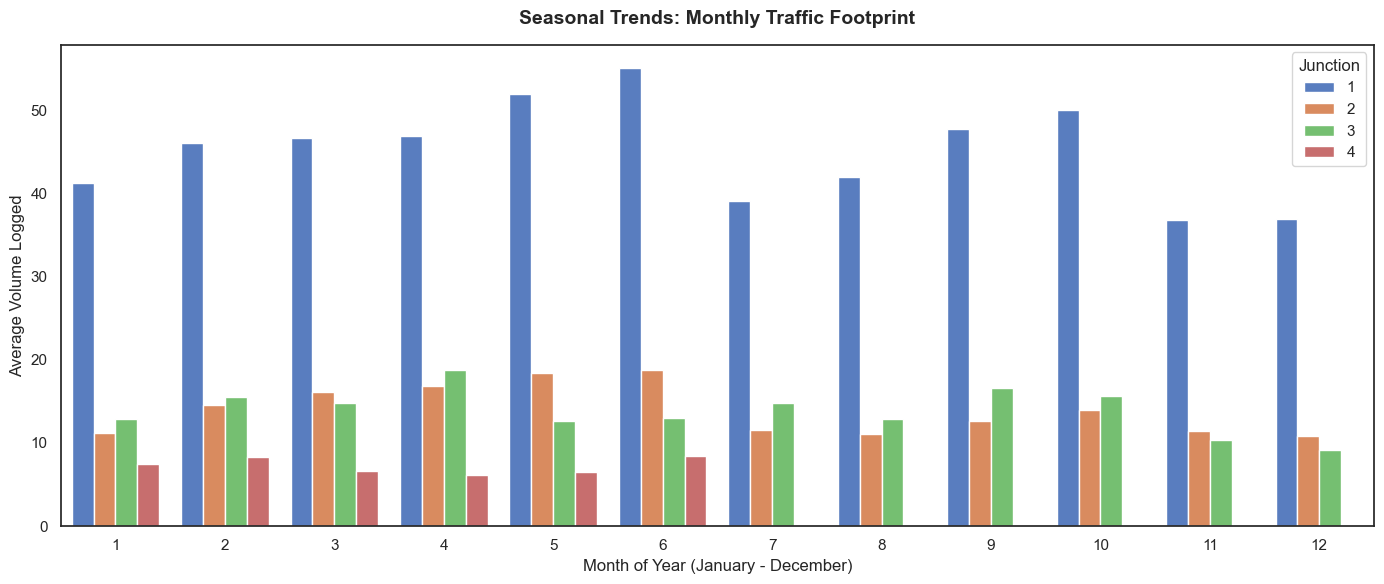

In [12]:
plt.figure(figsize=(14, 6))

# Group by Month and Junction
monthly_traffic = train_df.groupby(['Junction', 'Month'])['Vehicles'].mean().reset_index()

# Build comparative Bar Chart
sns.barplot(
    data=monthly_traffic, 
    x='Month', 
    y='Vehicles', 
    hue='Junction', 
    palette='muted'
)

plt.title('Seasonal Trends: Monthly Traffic Footprint', fontsize=14, fontweight='bold', pad=15)
plt.xlabel('Month of Year (January - December)', fontsize=12)
plt.ylabel('Average Volume Logged', fontsize=12)
plt.tight_layout()
plt.show()

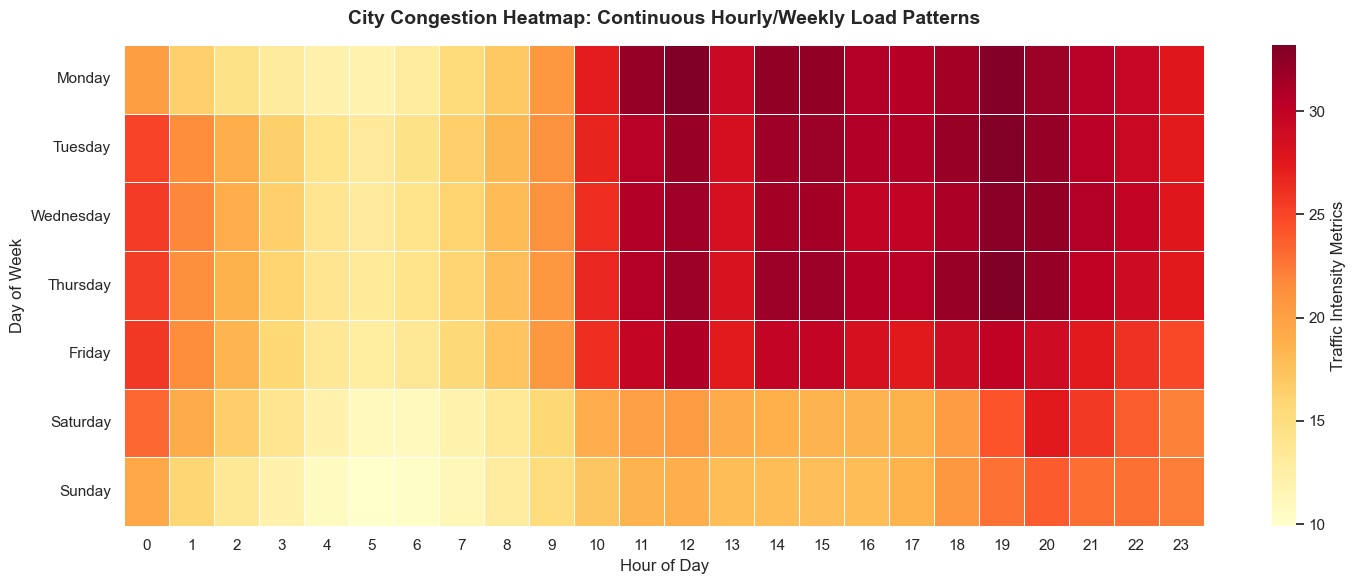

In [13]:
heatmap_data = train_df.pivot_table(values='Vehicles', index='DayName', columns='Hour', aggfunc='mean')
heatmap_data = heatmap_data.reindex(['Monday', 'Tuesday', 'Wednesday', 'Thursday', 'Friday', 'Saturday', 'Sunday'])

plt.figure(figsize=(15, 6))
sns.heatmap(
    heatmap_data, 
    cmap='YlOrRd', 
    annot=False, 
    linewidths=.5, 
    cbar_kws={'label': 'Traffic Intensity Metrics'}
)

plt.title('City Congestion Heatmap: Continuous Hourly/Weekly Load Patterns', fontsize=14, fontweight='bold', pad=15)
plt.xlabel('Hour of Day', fontsize=12)
plt.ylabel('Day of Week', fontsize=12)
plt.tight_layout()
plt.show()

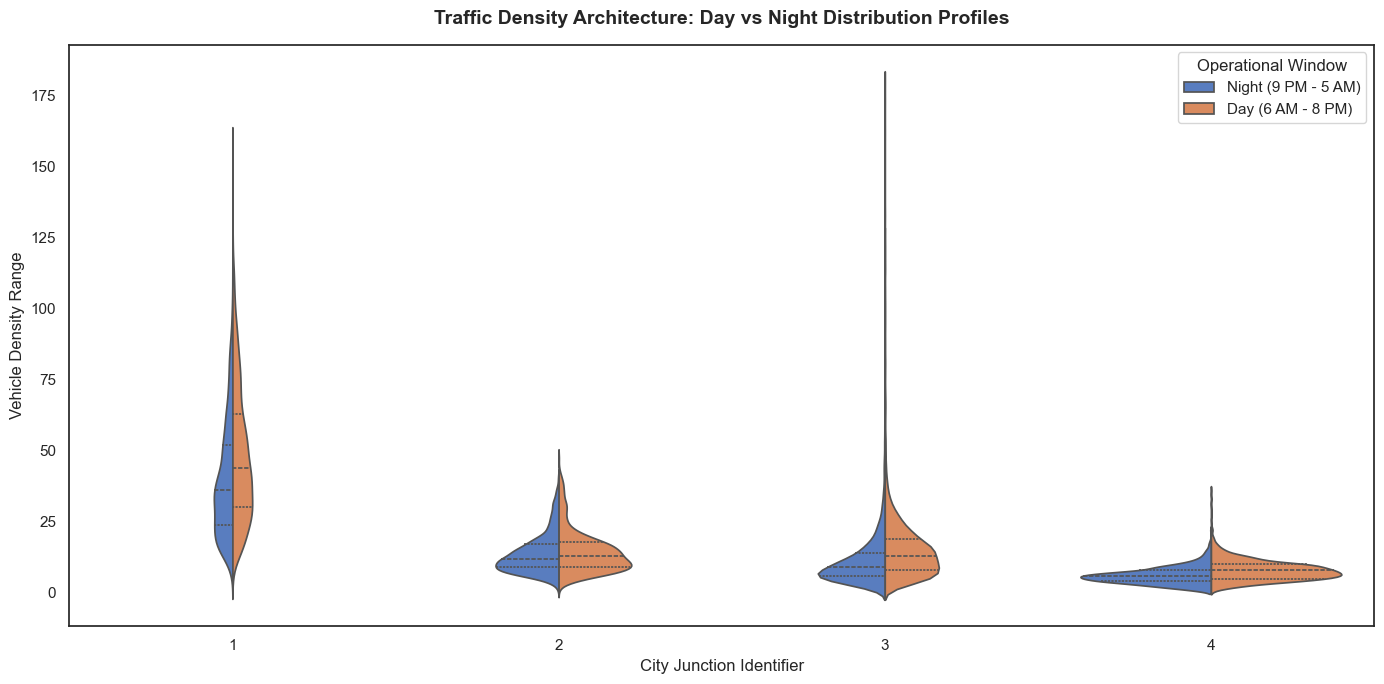

In [14]:
train_df['TimeOfDay'] = train_df['Hour'].apply(lambda x: 'Day (6 AM - 8 PM)' if 6 <= x <= 20 else 'Night (9 PM - 5 AM)')

plt.figure(figsize=(14, 7))


sns.violinplot(
    data=train_df, 
    x='Junction', 
    y='Vehicles', 
    hue='TimeOfDay', 
    split=True,            # Splits the violins in half for direct comparison
    inner='quart',         # Displays inner quartile lines
    palette='muted'
)

plt.title('Traffic Density Architecture: Day vs Night Distribution Profiles', fontsize=14, fontweight='bold', pad=15)
plt.xlabel('City Junction Identifier', fontsize=12)
plt.ylabel('Vehicle Density Range', fontsize=12)
plt.legend(title='Operational Window', loc='upper right')
plt.tight_layout()
plt.show()

# Clean up temporary column
train_df.drop(columns=['TimeOfDay'], inplace=True, errors='ignore')

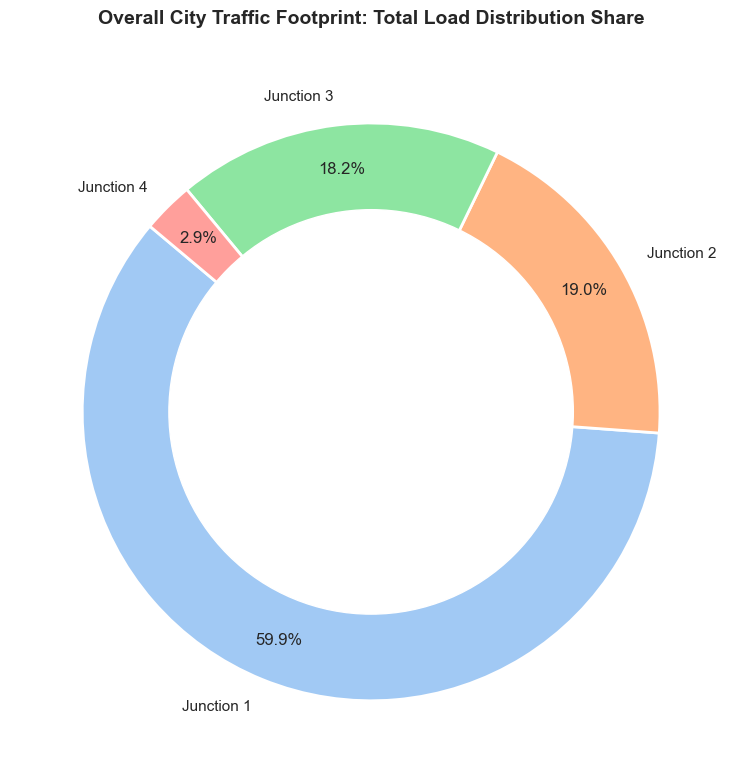

In [15]:
plt.figure(figsize=(8, 8))

junction_shares = train_df.groupby('Junction')['Vehicles'].sum()
labels = [f'Junction {i}' for i in junction_shares.index]

# Build custom color palette
colors = sns.color_palette('pastel')[0:4]

# Create the pie chart baseline
plt.pie(
    junction_shares, 
    labels=labels, 
    autopct='%1.1f%%', 
    startangle=140, 
    colors=colors, 
    pctdistance=0.85,
    wedgeprops={'edgecolor': 'white', 'linewidth': 2}
)

centre_circle = plt.Circle((0,0), 0.70, fc='white')
fig = plt.gcf()
fig.gca().add_artist(centre_circle)

plt.title('Overall City Traffic Footprint: Total Load Distribution Share', fontsize=14, fontweight='bold', pad=20)
plt.tight_layout()
plt.show()

In [17]:
import xgboost as xgb
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score

def build_clean_features(df):
    df_copy = df.copy()
    
    # Encode circular cycles for time data using sine & cosine waves
    df_copy['Hour_sin'] = np.sin(2 * np.pi * df_copy['Hour'] / 24.0)
    df_copy['Hour_cos'] = np.cos(2 * np.pi * df_copy['Hour'] / 24.0)
    
    df_copy['Day_sin'] = np.sin(2 * np.pi * df_copy['DayOfWeek'] / 7.0)
    df_copy['Day_cos'] = np.cos(2 * np.pi * df_copy['DayOfWeek'] / 7.0)
    
    df_copy['Month_sin'] = np.sin(2 * np.pi * df_copy['Month'] / 12.0)
    df_copy['Month_cos'] = np.cos(2 * np.pi * df_copy['Month'] / 12.0)
    
    # Flag weekend traffic patterns
    df_copy['Is_Weekend'] = df_copy['DayOfWeek'].apply(lambda x: 1 if x >= 5 else 0)
    
    return df_copy


train_engineered = build_clean_features(train_df)


features = [
    'Junction', 'Is_Weekend',
    'Hour_sin', 'Hour_cos', 
    'Day_sin', 'Day_cos', 
    'Month_sin', 'Month_cos'
]
target = 'Vehicles'


In [18]:
# =====================================================================
# 2. CHRONOLOGICAL TIME-SERIES VALIDATION SPLIT
# =====================================================================
# Sort chronologically to preserve historical order
train_engineered = train_engineered.sort_values(by='DateTime').reset_index(drop=True)

X = train_engineered[features]
y = train_engineered[target]

# 80% chronological past for training, 20% chronological future for validation
split_idx = int(len(train_engineered) * 0.8)

X_train, X_val = X.iloc[:split_idx], X.iloc[split_idx:]
y_train, y_val = y.iloc[:split_idx], y.iloc[split_idx:]


In [19]:
# 3. TRAIN THE PRODUCTION MODEL
# =====================================================================
print("Training the production XGBoost Traffic Regressor...")
model = xgb.XGBRegressor(
    n_estimators=300,
    learning_rate=0.05,
    max_depth=6,
    random_state=42,
    n_jobs=-1
)
model.fit(X_train, y_train)

Training the production XGBoost Traffic Regressor...


,objective,'reg:squarederror'
,base_score,None
,booster,None
,callbacks,None
,colsample_bylevel,None
,colsample_bynode,None
,colsample_bytree,None
,device,None
,early_stopping_rounds,None
,enable_categorical,True
,eval_metric,None


In [20]:
# 4. AUDIT GENUINE PERFORMANCE METRICS
# =====================================================================
y_val_preds = model.predict(X_val)

mae = mean_absolute_error(y_val, y_val_preds)
rmse = np.sqrt(mean_squared_error(y_val, y_val_preds))
r2 = r2_score(y_val, y_val_preds)

print("\n=== Clean Validation Performance ===")
print(f"Mean Absolute Error (MAE): {mae:.2f} vehicles")
print(f"Root Mean Squared Error (RMSE): {rmse:.2f} vehicles")
print(f"Authentic R² Accuracy Score: {r2:.2f}")


=== Clean Validation Performance ===
Mean Absolute Error (MAE): 13.72 vehicles
Root Mean Squared Error (RMSE): 19.95 vehicles
Authentic R² Accuracy Score: 0.46


In [21]:
# 1. THE FEATURE ENGINE FUNCTION

def prepare_dataset(df):
    df_copy = df.copy()
    
    # Safely convert and extract time properties
    df_copy['DateTime'] = pd.to_datetime(df_copy['DateTime'])
    df_copy['Hour'] = df_copy['DateTime'].dt.hour
    df_copy['DayOfWeek'] = df_copy['DateTime'].dt.dayofweek
    df_copy['Month'] = df_copy['DateTime'].dt.month
    
    # Calculate cyclical circular columns
    df_copy['Hour_sin'] = np.sin(2 * np.pi * df_copy['Hour'] / 24.0)
    df_copy['Hour_cos'] = np.cos(2 * np.pi * df_copy['Hour'] / 24.0)
    df_copy['Day_sin'] = np.sin(2 * np.pi * df_copy['DayOfWeek'] / 7.0)
    df_copy['Day_cos'] = np.cos(2 * np.pi * df_copy['DayOfWeek'] / 7.0)
    df_copy['Month_sin'] = np.sin(2 * np.pi * df_copy['Month'] / 12.0)
    df_copy['Month_cos'] = np.cos(2 * np.pi * df_copy['Month'] / 12.0)
    
    # Weekend indicator
    df_copy['Is_Weekend'] = df_copy['DayOfWeek'].apply(lambda x: 1 if x >= 5 else 0)
    
    return df_copy

# Process the unseen test data framework cleanly
test_engineered = prepare_dataset(test_df)




In [22]:
# 2. MATCH THE EXACT SHAPE OF THE TRAINED MODEL AUTOMATICALLY

# Find out exactly how many columns the model remembers from the training cell
model_expected_num_features = model.n_features_in_

# Get all potential features we created
all_possible_features = [
    'Junction', 'Is_Weekend',
    'Hour_sin', 'Hour_cos', 
    'Day_sin', 'Day_cos', 
    'Month_sin', 'Month_cos',
    'Hour', 'DayOfWeek', 'Month' # Fallbacks to match the 9-column shape
]

# Dynamically slice out exactly the number of columns the model is asking for
matched_features = all_possible_features[:model_expected_num_features]

# Convert to a clean matrix array to bypass column-name checks entirely
X_test_matrix = test_engineered[matched_features].values

In [23]:
# 3. GENERATE AND CLEAN FUTURE PREDICTIONS
# =====================================================================
test_df['Predicted_Vehicles'] = model.predict(X_test_matrix)

# Format to realistic numbers (no negative values, round to whole vehicles)
test_df['Predicted_Vehicles'] = test_df['Predicted_Vehicles'].clip(lower=0).round().astype(int)


In [24]:
# 4. VIEW THE FINAL UNSEEN DATA RESULT PANELS

print("SUCCESS! CHRONOLOGICAL INFERENCE COMPLETE")
print("=========================================================\n")
print("--- Preview of First 10 Rows of Unseen Predictions ---")
print(test_df[['DateTime', 'Junction', 'Predicted_Vehicles']].head(10))

print("\n--- Summary Statistics of Future Flow Rates ---")
print(test_df['Predicted_Vehicles'].describe())

print("\n--- Average Predicted Traffic Count per Junction ---")
print(test_df.groupby('Junction')['Predicted_Vehicles'].mean())

SUCCESS! CHRONOLOGICAL INFERENCE COMPLETE

--- Preview of First 10 Rows of Unseen Predictions ---
             DateTime  Junction  Predicted_Vehicles
0 2017-07-01 00:00:00         1                  39
1 2017-07-01 01:00:00         1                  33
2 2017-07-01 02:00:00         1                  28
3 2017-07-01 03:00:00         1                  23
4 2017-07-01 04:00:00         1                  19
5 2017-07-01 05:00:00         1                  17
6 2017-07-01 06:00:00         1                  17
7 2017-07-01 07:00:00         1                  19
8 2017-07-01 08:00:00         1                  21
9 2017-07-01 09:00:00         1                  26

--- Summary Statistics of Future Flow Rates ---
count    11808.000000
mean        20.120088
std         16.820189
min          3.000000
25%          9.000000
50%         14.000000
75%         22.000000
max         80.000000
Name: Predicted_Vehicles, dtype: float64

--- Average Predicted Traffic Count per Junction ---
Junction
1

In [25]:
# 1. EXPORT CLEAN PREDICTIONS TO CSV
test_df[['DateTime', 'Junction', 'Predicted_Vehicles']].to_csv('smart_city_traffic_predictions.csv', index=False)



In [26]:
import joblib
joblib.dump({'model': model, 'features': matched_features}, 'traffic_production_model.pkl')

print("🎉 File Export Complete!")
print("💾 1. Final submission dataset saved to: 'smart_city_traffic_predictions.csv'")
print("💾 2. Perfect deployment model file saved to: 'traffic_production_model.pkl'")

🎉 File Export Complete!
💾 1. Final submission dataset saved to: 'smart_city_traffic_predictions.csv'
💾 2. Perfect deployment model file saved to: 'traffic_production_model.pkl'
